In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

In [2]:
columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]


In [3]:
df=pd.read_csv('auto-mpg.csv',header=None,names=columns)

In [4]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1


In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [6]:
(df["horsepower"] == "?").any()

np.True_

In [7]:
(df['mpg']=="?").any()

np.False_

In [8]:
df["horsepower"].value_counts().get("?", 0)

np.int64(6)

In [9]:
df = df[df["horsepower"] != "?"].copy()

In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    str    
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 28.5 KB


In [11]:
df["horsepower"] = pd.to_numeric(df["horsepower"])

In [12]:
x = df[["horsepower"]]
y = df["mpg"]

In [13]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

In [14]:
dt_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

In [15]:
dt_model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [16]:
y_pred = dt_model.predict(x_test)
print("Decision Tree R2:", r2_score(y_test, y_pred))

Decision Tree R2: 0.6103557338163603


In [18]:
print(f"If horsepower is 150, then MPG is {dt_model.predict(pd.DataFrame({'horsepower': [150]}))[0]:.2f}")

If horsepower is 150, then MPG is 14.14


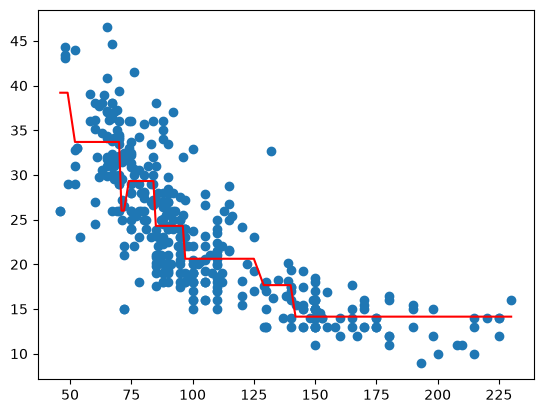

In [18]:
x_sorted = x.sort_values("horsepower")

plt.scatter(x, y)
plt.plot(
    x_sorted,
    dt_model.predict(x_sorted),
    color="red"
)
plt.show()

In [22]:
# as depth increase the chnaces of over fitting increases 
for depth in [2, 3, 4, 5, 6, 8, 10]:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    print(depth, r2_score(y_test, pred))

2 0.610676877997971
3 0.5521621583102407
4 0.4898885152888124
5 0.5102149902653021
6 0.49971505899737023
8 0.5026486717955475
10 0.49965349764617417


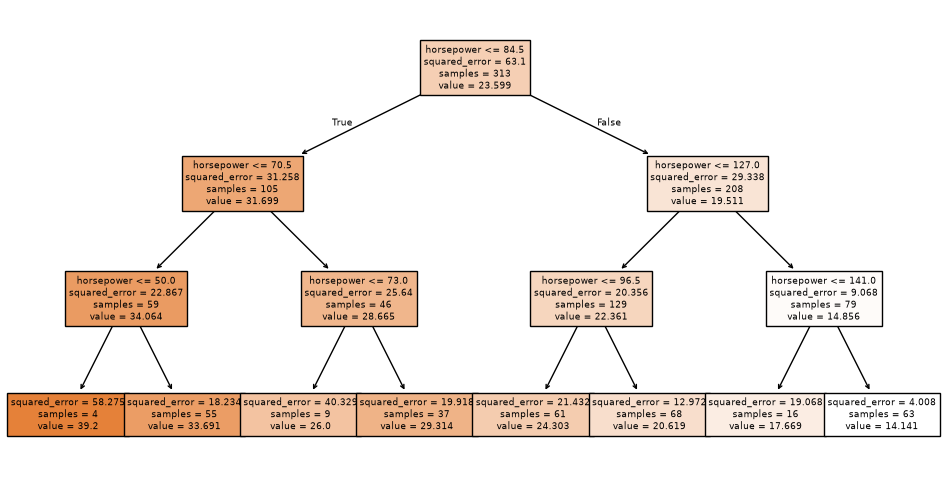

In [23]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plot_tree(dt_model, feature_names=["horsepower"], filled=True)
plt.show()

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# split into training + validation and test dat
x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

#  create validation data
x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=42
)

# try diff depths
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
best_score = float("-inf")
best_depth = None

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth, random_state=42
    )
    model.fit(x_train, y_train)

    val_pred = model.predict(x_val)
    score = r2_score(y_val, val_pred)

    print(f"Depth: {depth}, Validation R2: {score:.4f}")

    if score > best_score:
        best_score = score
        best_depth = depth

print("\nBest depth:", best_depth)
print("Best validation R2:", round(best_score, 4))

best_model = DecisionTreeRegressor(
    max_depth=best_depth, random_state=42
)
best_model.fit(x_train_val, y_train_val)


test_pred = best_model.predict(x_test)
print("Final Test R2:", r2_score(y_test, test_pred))

Depth: 1, Validation R2: 0.4307
Depth: 2, Validation R2: 0.5606
Depth: 3, Validation R2: 0.5421
Depth: 4, Validation R2: 0.5449
Depth: 5, Validation R2: 0.5145
Depth: 6, Validation R2: 0.5169
Depth: 8, Validation R2: 0.4883
Depth: 10, Validation R2: 0.4880
Depth: None, Validation R2: 0.4887

Best depth: 2
Best validation R2: 0.5606
Final Test R2: 0.618198661224346


# Decision Tree Regression — Complete Notes

## 1. What Is Decision Tree Regression?

Decision Tree Regression is a supervised Machine Learning algorithm used to predict continuous numerical values.

It learns a series of decision rules that split the dataset into smaller groups. Each final group is called a **leaf**, and the model predicts a numerical value for observations that reach that leaf.

Unlike Linear Regression, which fits a straight line, a Decision Tree can learn nonlinear relationships by splitting the input space into regions.

### Our Practice Example: Auto MPG Dataset

We used the Auto MPG dataset to predict fuel efficiency.

- `horsepower` — input feature (`X`)
- `mpg` — target (`y`)
- `max_depth=3` — limits the tree's depth

Our goal is to predict MPG based on horsepower.

## 2. How Does a Decision Tree Work?

A Decision Tree repeatedly asks questions about feature values.

For example, a learned tree might ask:

- Is horsepower less than or equal to a threshold?
- If yes, follow the left branch.
- If no, follow the right branch.
- Continue until a leaf is reached.
- Return the prediction stored in that leaf.

The actual thresholds are learned from the training data. They are not manually specified.

A regression tree typically predicts the **mean target value of the training samples in the leaf**.

## 3. Load and Prepare the Dataset

### Jupyter Notebook — Cell 1

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
```

### Jupyter Notebook — Cell 2

```python
columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]

df = pd.read_csv(
    "auto-mpg.csv",
    header=None,
    names=columns,
    na_values="?"
)

df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

df = df.dropna().copy()

print("Dataset shape:", df.shape)
df.head()
```

After cleaning, our dataset contains 392 rows.

## 4. Select the Feature and Target

### Jupyter Notebook — Cell 3

```python
X = df[["horsepower"]]
y = df["mpg"]

print("X shape:", X.shape)
print("y shape:", y.shape)
```

We use double brackets for `X` because scikit-learn expects a two-dimensional feature matrix.

## 5. Split the Data

### Jupyter Notebook — Cell 4

```python
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
```

The split gives 313 training samples and 79 test samples.

The tree learns its splitting rules from the training data. The test data is reserved for evaluating its predictions.

## 6. Train the Decision Tree Regressor

### Jupyter Notebook — Cell 5

```python
dt_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
```

In our practice, this model achieved an \(R^2\) score of approximately **0.6104**.

Your exact result should be checked by running the notebook with the same dataset and split.

### What does `max_depth=3` mean?

It limits the maximum number of edges from the root to a leaf to three.

- Smaller depth: simpler model, potentially underfits.
- Larger depth: more complex model, potentially overfits.
- No explicit depth limit: the tree can grow until other stopping conditions apply.

`max_depth` is a **hyperparameter** chosen before fitting.

## 7. How Does the Tree Choose a Split?

For regression, scikit-learn's default `criterion="squared_error"` evaluates splits using the reduction in squared-error impurity.

At a node, the algorithm considers candidate features and thresholds. For each candidate split, it calculates the weighted impurity of the resulting child nodes.

A good split creates child groups whose target values are more consistent than those in the parent.

The algorithm selects a split that maximizes the reduction in impurity, subject to the tree's constraints.

### Mean Squared Error at a Node

\[
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\bar y)^2
\]

Where:
- \(y_i\) = actual MPG for a sample.
- \(\bar y\) = mean MPG of the samples in that node.
- \(n\) = number of samples in the node.

### Weighted Impurity After a Split

\[
I_{\text{split}}=
\frac{n_L}{n}I_L+
\frac{n_R}{n}I_R
\]

Where:
- \(n_L\), \(n_R\) = sample counts in the left and right children.
- \(I_L\), \(I_R\) = their impurity values.
- \(n=n_L+n_R\).

The split is useful when the weighted child impurity is lower than the parent's impurity.

## 8. Visualize the Decision Tree

### Jupyter Notebook — Cell 6

```python
plt.figure(figsize=(18, 9))

plot_tree(
    dt_model,
    feature_names=["horsepower"],
    filled=True,
    rounded=True,
    precision=2
)

plt.title("Decision Tree Regressor")
plt.show()
```

### How to read the tree

Each node can display:

- **`horsepower <= threshold`**: the split condition.
- **`squared_error`**: impurity at that node.
- **`samples`**: number of training observations reaching that node.
- **`value`**: mean MPG of the training observations in that node.

The root is the first node. The leaves are the terminal nodes that produce predictions.

For an observation, follow the split rules until reaching a leaf. The leaf's `value` is the predicted MPG.

## 9. Visualize Predictions

### Jupyter Notebook — Cell 7

```python
x_sorted = X.sort_values("horsepower")

plt.scatter(X["horsepower"], y, alpha=0.5, label="Actual data")

plt.plot(
    x_sorted["horsepower"],
    dt_model.predict(x_sorted),
    color="red",
    label="Decision Tree prediction"
)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Decision Tree Regression: Horsepower vs MPG")
plt.legend()
plt.show()
```

The Decision Tree produces a **step-like prediction curve**, not a smooth line. Within each leaf's interval, the prediction is constant.

## 10. Evaluate the Model

### Jupyter Notebook — Cell 8

```python
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mse)
print("RMSE:", rmse)
```

- **R²:** measures performance relative to the test-set mean-prediction baseline.
- **MAE:** average absolute error in MPG.
- **MSE:** average squared error.
- **RMSE:** square root of MSE, expressed in MPG.

A higher R² and lower error metrics are generally preferable when comparing models on the same test set.

## 11. Experiment with Tree Depth

### Jupyter Notebook — Cell 9

```python
for depth in [1, 2, 3, 4, 5, 8, None]:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"Max depth: {depth}")
    print("Train R2:", r2_score(y_train, train_pred))
    print("Test R2:", r2_score(y_test, test_pred))
    print("-" * 30)
```

### How to interpret the results

- Shallow trees may miss important patterns.
- Deeper trees can fit the training data more closely.
- Very deep trees may memorize noise and generalize poorly.
- The best depth depends on the dataset.

For rigorous hyperparameter selection, use a validation set or cross-validation instead of repeatedly selecting the best result on the test set.

## 12. Important Hyperparameters

| Hyperparameter | Purpose |
|---|---|
| `max_depth` | Maximum depth of the tree |
| `min_samples_split` | Minimum number of samples required to split a node |
| `min_samples_leaf` | Minimum number of training samples required in a leaf |
| `max_leaf_nodes` | Limits the number of leaves |
| `criterion` | Impurity measure used to evaluate splits |
| `random_state` | Controls randomness for reproducibility |

These are configuration choices. The splitting thresholds and leaf predictions are learned during training.

## 13. Advantages and Limitations

### Advantages

- Captures nonlinear relationships.
- Does not require feature standardization for this tree-based model.
- Learns decision rules automatically.
- Can model interactions through sequential splits.
- Easy to visualize when the tree is small.

### Limitations

- Deep trees can overfit.
- Small data changes can produce a different tree.
- Predictions are piecewise constant, so the curve is not smooth.
- Individual trees can be less accurate than ensemble models.

## 14. Common Interview Questions

**1. What is Decision Tree Regression?**

A regression algorithm that recursively partitions the feature space and predicts a numerical value in each leaf.

**2. How does a regression tree choose a split?**

It evaluates candidate feature-threshold splits and chooses one that reduces weighted impurity.

**3. What does a leaf predict?**

With the default squared-error criterion, the mean target value of the training samples reaching that leaf.

**4. What does `max_depth` control?**

The maximum distance from the root to a leaf.

**5. Does a Decision Tree need feature scaling?**

Usually not. Its threshold comparisons are generally unaffected by ordinary scaling of a feature.

**6. Why do Decision Trees overfit?**

Deep trees can create narrow regions that fit individual training observations or noise.

**7. Why are tree predictions step-like?**

All observations reaching the same leaf receive the same prediction.

**8. What is the difference between a Decision Tree and Random Forest?**

A Decision Tree uses one tree. A Random Forest combines predictions from many trees to improve robustness and often generalization.

**9. What is `squared_error` in a tree plot?**

It is the node's mean squared-error impurity, based on target variation among training samples in that node.

## 15. Quick Revision

- We used Auto MPG to predict `mpg` from `horsepower`.
- We cleaned the dataset to 392 rows.
- We split it into 313 training and 79 test samples.
- We trained `DecisionTreeRegressor(max_depth=3)`.
- Our observed test R² was approximately 0.6104.
- The tree learns feature thresholds during training.
- Regression leaves predict the mean target under the default squared-error criterion.
- `max_depth` controls complexity.
- Tree predictions are piecewise constant.
- Deep trees can overfit.
- Evaluate models on unseen data and tune hyperparameters using validation data.
